In [8]:
import numpy as np
import pandas as pd
import scipy

from IPython.display import clear_output

import re
from pathlib import Path
import requests
import random
import time
import scipy
from bs4 import BeautifulSoup
import gc
import json
import glob

from tqdm import tqdm

# SJIF

In [11]:
index_df = pd.read_csv('../data/260123_sjifactor_all_journals.csv')
print(len(index_df))
index_df.head()

9214


,uid,title,title_href,issn,issn_href,country,flag_img_src,area,2023,2024,2025,2026,page_n
0,1,EPRA INTERNATIONAL JOURNAL OF ECONOMIC AND BUS...,./passport.php?id=17713,2347-9671,./passport.php?id=17713,NaN,./docs/flags/in.gif,SS,8.55,8.808,8.862,8.885,1
1,2,International Journal of Southern Economic Lig...,./passport.php?id=19268,2277-5692,./passport.php?id=19268,NaN,./docs/flags/in.gif,M,8.131,8.311,8.737,8.864,1
2,3,EPRA INTERNATIONAL JOURNAL OF RESEARCH & DEVEL...,./passport.php?id=18608,2455-7838,./passport.php?id=18608,NaN,./docs/flags/in.gif,M,8.574,8.675,8.688,8.863,1
3,4,EPRA International Journal of Economic Growth ...,./passport.php?id=18020,2321-6247,./passport.php?id=18020,NaN,./docs/flags/in.gif,SS,8.322,8.619,8.825,8.844,1
4,5,International Journal of Asian Economic Light,./passport.php?id=19293,2277-7741,./passport.php?id=19293,NaN,./docs/flags/in.gif,M,8.117,8.28,8.579,8.835,1


8.904
2.782


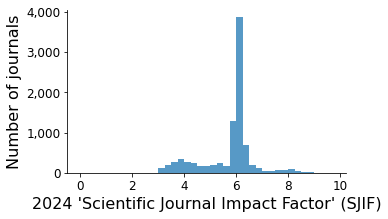

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

fig = plt.figure(figsize=(5,3))
ax = plt.gca()
year = 2024
sns.histplot(index_df[index_df[str(year)] != 'NC'][str(year)].astype(float), 
             bins=np.arange(0,10,0.25), linewidth=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(labelsize=12)
ax.set_xlabel(str(year) + " 'Scientific Journal Impact Factor' (SJIF)", fontsize=16)
ax.set_ylabel('Number of journals', fontsize=16)

ax.get_yaxis().set_major_formatter(
    mpl.ticker.FuncFormatter(lambda x, p: format(int(x), ',')))

print(index_df[index_df[str(year)] != 'NC'][str(year)].astype(float).max())
print(index_df[index_df[str(year)] != 'NC'][str(year)].astype(float).min())
#print(index_df[index_df[str(year)] != 'NC'][str(year)].astype(float).value_counts())

fig.savefig('../img/260714_sjif_' + str(year) + '_distribution.png', dpi=200, bbox_inches='tight')
fig.savefig('../img/260714_sjif_' + str(year) + '_distribution.pdf', bbox_inches='tight')

In [398]:
collect_att = []
for filepath in glob.glob('../data/260123_sjifactor_journal_page_attributes_[0-9]*.csv'):
    att_df = pd.read_csv(filepath)
    collect_att.append(att_df)
att_df = pd.concat(collect_att).reset_index(drop=True)
att_df.to_csv('../data/260123_sjifactor_journal_page_attributes_all.csv', index=False)

In [399]:
att_df['key'].value_counts().head(12)

Frequency                                                                          9214
SJIFactor.com                                                                      9214
Basic information                                                                  9214
Main title                                                                         9214
ISSN                                                                               9214
Country                                                                            9214
The journal is indexed in:                                                         9214
License                                                                            9214
Texts availability                                                                 9214
URL                                                                                9208
SJIF 2026: Under evaluation  Area: Multidisciplinary  Evaluated version: online    6486
Journal's description           

In [400]:
att_df[att_df['key'] == 'ISSN']['value'].apply(len).value_counts()

13    6597
29    2617
Name: value, dtype: int64

In [401]:
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-[0-9][0-9][0-9][0-9xX]%?)""")
matches = issn_pattern.finditer('2347-9671 (E) / 2349-0187 (P)')
for m in matches:
    issn = m.group('issn')
    print(issn)

2347-9671
2349-0187


In [406]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = att_df[att_df['key'] == 'ISSN'].copy()
for uid, issn_str in tqdm(zip(issn_slice['sjif_jid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(issn_str)
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

# country
country_df = att_df[att_df['key'] == 'Country'].rename(columns={'sjif_jid':'uid'})
country_df['key'] = 'country'

# url
url_df = att_df[att_df['key'] == 'URL'].rename(columns={'sjif_jid':'uid'})
url_df['key'] = 'url'

# title
title_df = att_df[att_df['key'] == 'Main title'].rename(columns={'sjif_jid':'uid'})
title_df['key'] = 'title'

9214it [00:01, 5646.51it/s]


In [248]:
combo_df = pd.concat([issn_df, country_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'sjif'

In [249]:
combo_df[['service', 'uid', 'key', 'value']].to_csv('../data/260123_sjifactor_journal_select_properties.csv', index=False)

# ESJI

In [385]:
index_df = pd.read_csv('../data/260313_esji_all_journals.csv')
att_df = index_df.copy()
index_df.head()

,uid,cover,all_unstructured,impact_factor,title,url,info_text,imgs,page_n
0,1.0,Upload cover,Theoretical & Applied Science eISSN 2409-0085p...,8.100 (2024) 8.502 (2023) 8.771 (2022) 9.035 (...,Theoretical & Applied Science,http://www.T-Science.org,<h5>eISSN 2409-0085\npISSN 2308-4944\nInternat...,"/cover/1.jpg, /pic/oa.png, /pic/soi.gif, /pic/...",0
1,2.0,Upload cover,Science Editing eISSN 2288-7474pISSN 2288-8063...,Evaluation not done by ESJI yet Calculate now,Science Editing,http://www.escienceediting.org/,<h5>eISSN 2288-7474\npISSN 2288-8063\nKorean C...,"/cover/2.jpg, /pic/oa.png, /pic/doi.gif",0
2,3.0,Upload cover,ISJ Real Science IA RS http://esjindex.org/sea...,Evaluation not done by ESJI yet Calculate now,ISJ Real Science,http://Real-Sc.org,"<h5>IA RS\n\n<a href=""http://esjindex.org/sear...","/cover/3.jpg, /pic/oa.png, /pic/soi.gif, /pic/...",0
3,13.0,Upload cover,El-Bahith Review eISSN 1112-3613pISSN 1112-361...,Evaluation not done by ESJI yet Calculate now,El-Bahith Review,http://revues.univ-ouargla.dz/index.php/acceil...,<h5>eISSN 1112-3613\npISSN 1112-3613\nKsdi Mer...,"/cover/13.jpg, /pic/oa.png",0
4,14.0,Upload cover,PAKISTAN JOURNAL OF NUCLEAR MEDICINE eISSN 230...,Evaluation not done by ESJI yet Calculate now,PAKISTAN JOURNAL OF NUCLEAR MEDICINE,http://www.pjnm.net,<h5>eISSN 2305-1620\npISSN 2221-0288\nPakistan...,"/cover/14.jpg, /pic/oa.png",0


In [394]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = index_df.copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['all_unstructured'].values)):
    matches = issn_pattern.finditer(issn_str)
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
# none

# url
url_df = att_df[['uid', 'url']].rename(columns={'url':'value'})
url_df['key'] = 'url'

# title
title_df = att_df[['uid', 'title']].rename(columns={'title':'value'})
title_df['key'] = 'title'

8587it [00:01, 4365.02it/s]


In [252]:
combo_df = pd.concat([issn_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'esji'

In [253]:
combo_df.to_csv('../data/260313_esji_journal_select_properties.csv', index=False)

In [254]:
combo_df

,uid,key,value,service
0,1.0,issn,2409-0085,esji
1,1.0,issn,2308-4944,esji
2,2.0,issn,2288-7474,esji
3,2.0,issn,2288-8063,esji
4,13.0,issn,1112-3613,esji
...,...,...,...,...
29645,8699.0,title,Revista OWL (OWL Journal) - REVISTA INTERDISCI...,esji
29646,8700.0,title,Sciences & Education,esji
29647,8701.0,title,Elmi Əsərlər / Scientific Works of Azerbaijan ...,esji
29648,8702.0,title,Gomal Journal of Life Sciences,esji


# IFSIJ

In [372]:
index_df = pd.read_csv('../data/260313_ifsij_all_journals.csv')
index_df['uid'] = range(len(index_df))
att_df = index_df.copy()
index_df.head()

,title,issn,url,country,2022,2023,2024,2025,2026,uid
0,ARC Journal of Nutrition and Growth,2455-2550,https://www.arcjournals.org/journal-of-nutriti...,India,4.931,5.451,5.525,5.775,NC,0
1,Scientific Notes of Sumy State Pedagogical Uni...,2413-8800,http://scinotesgeoen.at.ua,Ukraine,5.131,5.651,5.725,6.025,NC,1
2,The Scientific Issues of Ternopil Volodymyr Hn...,2415-3605,http://nzp.tnpu.edu.ua/,Ukraine,5.161,5.681,5.755,5.985,NC,2
3,Dnipropetrovsk University bulletin. History & ...,2414-9578,http://www.via.dp.ua,Ukraine,4.531,5.051,5.125,5.465,NC,3
4,Journal of Economics Business and Political Re...,2564-7466,http://dergipark.gov.tr/iktisad,Turkey,4.631,5.151,5.225,5.625,NC,4


In [381]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = index_df.copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['issn'].values)):
    matches = issn_pattern.finditer(issn_str)
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
country_df = att_df[['uid', 'country']].rename(columns={'country':'value'})
country_df['key'] = 'country'

# url
url_df = att_df[['uid', 'url']].rename(columns={'url':'value'})
url_df['key'] = 'url'

# title
title_df = att_df[['uid', 'title']].rename(columns={'title':'value'})
title_df['key'] = 'title'

881it [00:00, 8007.43it/s]


In [257]:
combo_df = pd.concat([issn_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'ifsij'

In [258]:
combo_df[['service', 'uid', 'key', 'value']].to_csv('../data/260313_ifsij_journal_select_properties.csv', index=False)

In [259]:
combo_df

,uid,key,value,service
0,0,issn,2455-2550,ifsij
1,1,issn,2413-8800,ifsij
2,2,issn,2415-3605,ifsij
3,3,issn,2414-9578,ifsij
4,4,issn,2564-7466,ifsij
...,...,...,...,...
2614,876,title,"Eureka Journal of Civil, Architecture and Urba...",ifsij
2615,877,title,"Eureka Journal of Geoscience, Materials & Reso...",ifsij
2616,878,title,Eureka Journal of Computing Science & Digital ...,ifsij
2617,879,title,Eureka Journal of Artificial Intelligence and ...,ifsij


# International Impact Factor Services

In [363]:
index_df = pd.read_csv('../data/260323_international_impact_factor_services_all_journals.csv')
index_df.head()

,Journal Name,ISSN,Indexed,Impact Factor,Valid,title_href,page_n
0,World Journal of Pharmacy and Pharmaceutical S...,2278-4357,https://impactfactorservice.com/assets/images/...,Under Evaluation,"Dec 01, 2014",https://impactfactorservice.com/home/journal/19,1
1,World Journal of Pharmaceutical Research,2277-7105,https://impactfactorservice.com/assets/images/...,Under Evaluation,"Dec 01, 2014",https://impactfactorservice.com/home/journal/20,1
2,International Journal of Current Microbiology ...,2319-7706,https://impactfactorservice.com/assets/images/...,Under Evaluation,"Dec 01, 2014",https://impactfactorservice.com/home/journal/21,1
3,International Journal of Current Research and ...,2347-3215,https://impactfactorservice.com/assets/images/...,Under Evaluation,"Dec 01, 2014",https://impactfactorservice.com/home/journal/22,1
4,World Journal of Pharmaceutical Sciences,2321-3310,https://impactfactorservice.com/assets/images/...,Under Evaluation,"Dec 01, 2014",https://impactfactorservice.com/home/journal/23,1


In [364]:
collect_att = []
for filepath in glob.glob('../data/260323_international_impact_factor_services_journal_page_attributes_[0-9]*.csv'):
    att_df = pd.read_csv(filepath)
    collect_att.append(att_df)
att_df = pd.concat(collect_att).reset_index(drop=True)
att_df.to_csv('../data/260323_international_impact_factor_services_journal_page_attributes_all.csv', index=False)

In [365]:
att_df['uid'] = att_df['url'].apply(lambda x: int(x.split('/')[-1]))

In [366]:
att_df

,key,value,url,journal_title,uid
0,ISSN,2278-4357,https://impactfactorservice.com/home/journal/19,World Journal of Pharmacy and Pharmaceutical S...,19
1,Country,Bulgaria,https://impactfactorservice.com/home/journal/19,World Journal of Pharmacy and Pharmaceutical S...,19
2,Impact Factor,Under Evaluation,https://impactfactorservice.com/home/journal/19,World Journal of Pharmacy and Pharmaceutical S...,19
3,Publication Year,2012,https://impactfactorservice.com/home/journal/19,World Journal of Pharmacy and Pharmaceutical S...,19
4,Indexed,NaN,https://impactfactorservice.com/home/journal/19,World Journal of Pharmacy and Pharmaceutical S...,19
...,...,...,...,...,...
14095,Country,USA,https://impactfactorservice.com/home/journal/945,Journal of Applied Biotechnology,945
14096,Impact Factor,Under Evaluation,https://impactfactorservice.com/home/journal/945,Journal of Applied Biotechnology,945
14097,Publication Year,2013,https://impactfactorservice.com/home/journal/945,Journal of Applied Biotechnology,945
14098,Indexed,NaN,https://impactfactorservice.com/home/journal/945,Journal of Applied Biotechnology,945


In [370]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = att_df[att_df['key'] == 'ISSN'].copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

# country
country_df = att_df[att_df['key'] == 'Country'].rename(columns={'sjif_jid':'uid'})
country_df['key'] = 'country'

# url
url_df = att_df[att_df['key'] == 'Website'].rename(columns={'sjif_jid':'uid'})
url_df['key'] = 'url'

# title
title_df = att_df[['uid', 'journal_title']].rename(columns={'journal_title':'value'}).drop_duplicates()
title_df['key'] = 'title'

2350it [00:00, 5563.17it/s]


In [265]:
combo_df = pd.concat([issn_df, country_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'international_impact_factor_services'

In [266]:
combo_df['key'].value_counts()

country    2350
url        2350
title      2350
issn       2324
Name: key, dtype: int64

In [267]:
combo_df

,uid,key,value,url,journal_title,service
0,19,issn,2278-4357,NaN,NaN,international_impact_factor_services
1,20,issn,2277-7105,NaN,NaN,international_impact_factor_services
2,21,issn,2319-7706,NaN,NaN,international_impact_factor_services
3,22,issn,2347-3215,NaN,NaN,international_impact_factor_services
4,23,issn,2321-3310,NaN,NaN,international_impact_factor_services
...,...,...,...,...,...,...
9369,941,title,Journal of Bio Innovation,NaN,NaN,international_impact_factor_services
9370,942,title,International Journal of Engineering and Manag...,NaN,NaN,international_impact_factor_services
9371,943,title,International Research Journal of Pharmacy,NaN,NaN,international_impact_factor_services
9372,944,title,Journal of Social Science Studies,NaN,NaN,international_impact_factor_services


In [268]:
combo_df[['service', 'uid', 'key', 'value']].to_csv('../data/260323_international_impact_factor_services_journal_select_properties.csv', index=False)

# International CItation Index

In [354]:
index_df = pd.read_csv('../data/260324_international_citation_index_all_journals.csv')
index_df.head()

,Title,ISSN,Status,Country,2014,2015,2016,2017,2018,View Details,View Details.1,title_href
0,Altus CiÃªncias,2318-4817,Indexed,Brazil,NaN,NaN,NaN,NaN,2.2037,View Details,View Certificate,journal-details.php?journal_id=206
1,International Journal of Humanities and Cultur...,2356-5926,Indexed,Tunisia,NaN,NaN,NaN,NaN,5.7203,View Details,View Certificate,journal-details.php?journal_id=333
2,Research Journal of English Language and Liter...,2321-3108,Indexed,India,NaN,NaN,NaN,6.8992,NaN,View Details,View Certificate,journal-details.php?journal_id=266
3,Akdeniz TÄ±p Dergisi,1300-1779,Indexed,Turkey,NaN,NaN,NaN,NaN,2.3204,View Details,View Certificate,#
4,American Journal of Essential Oil and Natural ...,2321-9114,Indexed,India,NaN,NaN,1.6543,2.2135,NaN,View Details,View Certificate,journal-details.php?journal_id=62


In [355]:
collect_att = []
for filepath in glob.glob('../data/260324_international_citation_index_journal_page_attributes_[0-9]*.csv'):
    att_df = pd.read_csv(filepath)
    collect_att.append(att_df)
att_df = pd.concat(collect_att).reset_index(drop=True)
att_df.to_csv('../data/260324_international_citation_index_journal_page_attributes_all.csv', index=False)

In [356]:
att_df['uid'] = att_df['title_href'].apply(lambda x: int(x.split('=')[-1]))

In [357]:
att_df['key'].value_counts()

Title                           141
Online ISSN / Print ISSN        141
Chief Editor                    141
Publisher Name                  141
Journal Description             141
Organization Contact Details    141
URL                             141
Country                         141
Email                           141
Language                        141
Area Of Specialization          141
Starting Year                   141
Online Availability             141
Accessibility                   141
Content Accessibility           141
Contact No.                       1
Name: key, dtype: int64

In [358]:
att_df[att_df['key'] == 'Online ISSN / Print ISSN']['value'].apply(len).value_counts()

9     122
11     13
21      2
19      1
14      1
12      1
27      1
Name: value, dtype: int64

In [359]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = att_df[att_df['key'] == 'Online ISSN / Print ISSN'].copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(issn_str)
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

# country
country_df = att_df[att_df['key'] == 'Country'].rename(columns={'sjif_jid':'uid'})
country_df['key'] = 'country'

# url
url_df = att_df[att_df['key'] == 'URL'].rename(columns={'sjif_jid':'uid'})
url_df['key'] = 'url'

# title
title_df = att_df[att_df['key'] == 'Title'].rename(columns={'sjif_jid':'uid'})
title_df['key'] = 'title'

141it [00:00, 8223.44it/s]


In [360]:
combo_df = pd.concat([issn_df, country_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'international_citation_index'

In [303]:
combo_df[['service', 'uid', 'key', 'value']]\
.to_csv('../data/260324_international_citation_index_journal_select_properties.csv', index=False)

# DRJI

In [408]:
index_df = pd.read_csv('../data/260324_drji_all_journals.csv')
index_df.head()

,country,journal_data,title,title_href,website
0,India,Dr. M Viswanathan,International Journal of Intellectual Advancem...,JournalProfile.aspx?jid=2348-2079,www.ijiarec.com
1,India,Dr.N.Sriram,International Journal of Allied Medical Scienc...,JournalProfile.aspx?jid=2347-6567,www.ijamscr.com
2,India,Dr.N.Sriram,Journal of Pharma Creations (JPC),JournalProfile.aspx?jid=2348-6295,www.pharmacreations.com
3,India,Dr.K.B.CHANDRASEKHAR,International Journal of Pharmacy & Industrial...,JournalProfile.aspx?jid=2231-3656,www.ijpir.com
4,United Arab Emirates,Saroj Arora,Journal of Botanical Papers,JournalProfile.aspx?jid=2519-5271,https://scigatejournals.com/publications/index...


In [409]:
collect_att = []
for filepath in glob.glob('../data/260324_drji_journal_page_attributes_[0-9]*.csv'):
    att_df = pd.read_csv(filepath)
    collect_att.append(att_df)
att_df = pd.concat(collect_att).reset_index(drop=True)
att_df.to_csv('../data/260324_drji_journal_page_attributes_all.csv', index=False)

In [410]:
att_df['uid'] = att_df['title_href'].apply(lambda x: x.split('=')[-1])

In [411]:
issn_slice

,key,value,sjif_jid
5,ISSN,2347-9671 (E) / 2349-0187 (P),17713
24,ISSN,2277-5692 (E),19268
43,ISSN,2455-7838 (E),18608
62,ISSN,2321-6247 (P),18020
81,ISSN,2277-7741 (E),19293
...,...,...,...
126760,ISSN,3080-2504 (E),25353
126771,ISSN,3108-4303 (E),25356
126784,ISSN,3067-2325 (E),25364
126797,ISSN,3067-3089 (E),25365


In [412]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = att_df[att_df['key'] == 'ISSN No. :'].copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
country_df = att_df[att_df['key'] == 'Country :'].rename(columns={'sjif_jid':'uid'})
country_df['key'] = 'country'

# url
url_df = att_df[att_df['key'] == 'Journal URL :'].rename(columns={'sjif_jid':'uid'})
url_df['key'] = 'url'

# title
title_df = att_df[att_df['key'] == 'Journal Title :'].rename(columns={'sjif_jid':'uid'})
title_df['key'] = 'title'

8914it [00:01, 8414.97it/s]


In [413]:
issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

In [414]:
combo_df = pd.concat([issn_df, country_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'drji'

In [417]:
combo_df[['service', 'uid', 'key', 'value']]\
.to_csv('../data/260324_drji_journal_select_properties.csv', index=False)

# IFJ

Has "all journals" and "under evaluation" journals

In [427]:
index_df = pd.read_csv('../data/260324_ifj_all_journals.csv')
index_df['uid'] = range(len(index_df))
att_df = index_df.copy()

In [428]:
index_df['uid'] = range(len(index_df))

In [435]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = index_df.copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['ISSN Number'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
# none

# url
# none

# title
title_df = att_df[['uid', 'Title']].rename(columns={'Title':'value'})
title_df['key'] = 'title'

290it [00:00, 7736.65it/s]


In [440]:
combo_df_all = pd.concat([issn_df, title_df]).reset_index(drop=True)
# combo_df['service'] = 'ifj'

In [450]:
index_df = pd.read_csv('../data/260324_ifj_under_evaluation_journals.csv')
index_df['uid'] = range(combo_df_all['uid'].max(), combo_df_all['uid'].max()+len(index_df))
att_df = index_df.copy()

In [456]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = index_df.copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['info_text'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
# none

# url
# none

# title
title_df = att_df[['uid', 'info_text']]
title_df['value'] = title_df['info_text'].apply(lambda x: x.split('\n')[0])
title_df['key'] = 'title'

354it [00:00, 7245.60it/s]


In [457]:
combo_df_eval = pd.concat([issn_df, title_df]).reset_index(drop=True)
# combo_df['service'] = 'ifj'

In [459]:
combo_df = pd.concat([combo_df_all, combo_df_eval])
combo_df['service'] = 'ifj'

In [464]:
combo_df[['service', 'uid', 'key', 'value']]\
.to_csv('../data/260324_ifj_journal_select_properties.csv', index=False)

# Cosmos

In [483]:
index_df = pd.read_csv('../data/260324_cosmos_all_journals.csv')
index_df['uid'] = index_df['title_href'].apply(lambda x: int(x.split('/')[-1].split('.')[0]))

In [506]:
collect_att = []
for filepath in glob.glob('../data/260324_cosmos_journal_page_attributes_[0-9]*.csv'):
    att_df = pd.read_csv(filepath)
    collect_att.append(att_df)
att_df = pd.concat(collect_att).reset_index(drop=True)
# missing valeus in title_href
att_df['title_href'] = att_df['title_href'].ffill()
att_df.to_csv('../data/260324_cosmos_journal_page_attributes_all.csv', index=False)

In [508]:
att_df['uid'] = att_df['title_href'].apply(lambda x: int(x.split('/')[-1].split('.')[0]))

In [512]:
att_df['key'].value_counts()

Journal Name                 6642
ISSN (P)                     6642
Journal Description          6642
Cosmos Impact Factor         6642
Phone No.                    6642
Email                        6642
Indexed                      6642
Editor                       6642
Web Site                     6642
Year of First Publication    6642
Journal Language             6642
Organization                 6642
Area of specialization       6642
Journal Discipline           6642
Frequency                    6642
Country                      6642
ISSN (O)                     6642
website_href                 6642
Name: key, dtype: int64

In [509]:
# issn
collect_issns = []
issn_pattern = re.compile("""(?P<issn>[0-9][0-9][0-9][0-9]-*[0-9][0-9][0-9][0-9xX]%?)""")
issn_slice = att_df[att_df['key'] == 'ISSN (P)'].copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
        
issn_slice = att_df[att_df['key'] == 'ISSN (O)'].copy()
for uid, issn_str in tqdm(zip(issn_slice['uid'].values, issn_slice['value'].values)):
    matches = issn_pattern.finditer(str(issn_str))
    for m in matches:
        issn = m.group('issn')
        collect_issns.append(pd.DataFrame({'uid':[uid], 'key':['issn'], 'value':[issn]}))
                
issn_df = pd.concat(collect_issns)

issn_df.loc[~issn_df['value'].str.contains('-'), 'value'] = \
issn_df.loc[~issn_df['value'].str.contains('-')]['value'].apply(lambda x: x[0:4] + '-' + x[4:])

# country
country_df = att_df[att_df['key'] == 'Country'].rename(columns={'sjif_jid':'uid'})
country_df['key'] = 'country'

# url
url_df = att_df[att_df['key'] == 'website_href'].rename(columns={'sjif_jid':'uid'})
url_df['key'] = 'url'

# title
title_df = att_df[att_df['key'] == 'Journal Name'].rename(columns={'sjif_jid':'uid'})
title_df['key'] = 'title'

6642it [00:01, 6392.28it/s]
6642it [00:00, 16241.36it/s]


In [513]:
combo_df = pd.concat([issn_df, country_df, url_df, title_df]).reset_index(drop=True)
combo_df['service'] = 'cosmos'

In [515]:
combo_df[['service', 'uid', 'key', 'value']]\
.to_csv('../data/260324_cosmos_journal_select_properties.csv', index=False)

In [516]:
combo_df

,uid,key,value,title_href,service
0,25,issn,2277-1808,NaN,cosmos
1,26,issn,2277-1581,NaN,cosmos
2,27,issn,2319-6890,NaN,cosmos
3,28,issn,2348-5221,NaN,cosmos
4,29,issn,2277-3657,NaN,cosmos
...,...,...,...,...,...
29886,1426,title,IJRDO-Journal Of Business Management,https://cosmosimpactfactor.com/page/journals_d...,cosmos
29887,1427,title,IJRDO-Journal Of Biological Science.,https://cosmosimpactfactor.com/page/journals_d...,cosmos
29888,1428,title,IJRDO-Journal Of Agricultural And Research,https://cosmosimpactfactor.com/page/journals_d...,cosmos
29889,1430,title,Telangana Journal of Psychiatry,https://cosmosimpactfactor.com/page/journals_d...,cosmos


# Combine

In [539]:
collect = []
for filepath in glob.glob('../data/*_journal_select_properties.csv'):
    att_df = pd.read_csv(filepath)
    collect.append(att_df)
combo_df = pd.concat(collect).reset_index(drop=True)
#combo_df.to_csv('../data/260711_combined_journal_select_properties.csv', index=False)

In [549]:
issn_df = combo_df[combo_df['key'] == 'issn'].copy()
non_issn_df = combo_df[combo_df['key'] != 'issn'].copy()

issn_df['value'] = issn_df['value'].apply(lambda x: x.replace('--', '-'))
combo_df = pd.concat([issn_df, non_issn_df])

In [550]:
combo_df.to_csv('../data/260711_combined_journal_select_properties.csv', index=False)

In [535]:
combo_df[combo_df['key'] == 'issn'].groupby('value')['service'].nunique().sort_values()

value
9999-6666    1
2449-1780    1
2449-1799    1
2449-1802    1
2449-1810    1
            ..
2277-9469    7
2581-3250    7
2394-3696    7
2319-5622    7
2349-0659    8
Name: service, Length: 26669, dtype: int64

In [536]:
issn_df_slice = combo_df[combo_df['value'] == '2277-9469']
pd.merge(issn_df_slice, combo_df[combo_df['key'] == 'title'], on=['service', 'uid'])

,service,uid,key_x,value_x,key_y,value_y
0,sjif,1301,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
1,esji,328.0,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
2,ifsij,143,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
3,international_impact_factor_services,85,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
4,cosmos,1644,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
5,drji,2277-9469,issn,2277-9469,title,Journal of Scientific Research in Pharmacy
6,ifj,323,issn,2277-9469,title,Journal of Scientific Research in Pharmacy (JSRP)
